# BDD100K: exploratory data analysis

What's in the detection labels, and what it means for training a small YOLO on a 6 GB GPU.

Input: the label index built by `python data/bdd100k_index.py`:

- `data/bdd100k/index/images.parquet`: one row per image (split, weather, scene, time of day, box and lane counts)
- `data/bdd100k/index/boxes.parquet`: one row per box (image, category, corners in pixels, occluded, truncated)

All images are 1280×720. Splits: 70k train, 10k val (the test split has no public labels).

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "bdd100k"

images = pd.read_parquet(DATA / "index" / "images.parquet")
boxes = pd.read_parquet(DATA / "index" / "boxes.parquet")

# Chart style: one blue for magnitudes, a blue ramp for ordered buckets, quiet axes and grid
BLUE = "#2a78d6"
RAMP = ["#86b6ef", "#3987e5", "#1c5cab"]  # small -> medium -> large
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 90,
})


def hbar(ax, series, title, fmt="{:,.0f}", log=False):
    """Horizontal bars, largest on top, each bar labelled with its value."""
    s = series.sort_values()
    ax.barh(s.index.astype(str), s.values, color=BLUE, height=0.65)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    if log:
        ax.set_xscale("log")
    for y, v in enumerate(s.values):
        ax.annotate(fmt.format(v), (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
    ax.margins(x=0.15)


print(f"{len(images):,} images, {len(boxes):,} boxes")
images.groupby("split", observed=True).agg(images=("image_id", "size"), boxes=("n_boxes", "sum"))

/home/karthik/autonomous-driving-perception-stack/.venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


80,000 images, 1,473,983 boxes


,images,boxes
split,,
train,70000,1288405
val,10000,185578


## 1. Class balance

Two different counts matter:

- **boxes per class**: how many examples the loss sees
- **images containing the class**: how often the class appears at all, which is what sampling a training subset controls

The x-axis is logarithmic: each gridline is 10× the previous one, otherwise everything except `car` would be an invisible sliver.

car : motor = 238 : 1,  car : train = 5,251 : 1


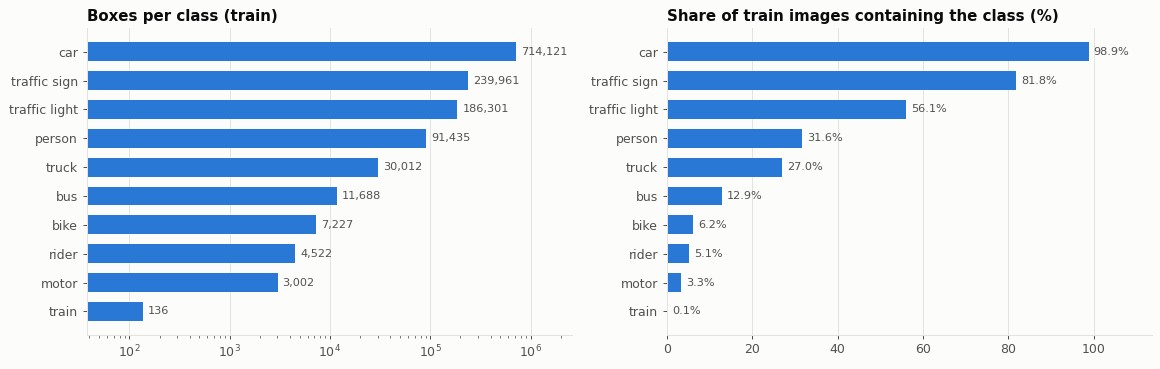

In [2]:
train_boxes = boxes[boxes.split == "train"]
train_images = images[images.split == "train"]

box_counts = train_boxes.category.value_counts()
image_counts = train_boxes.groupby("category", observed=True).image_id.nunique()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hbar(axes[0], box_counts, "Boxes per class (train)", log=True)
hbar(axes[1], image_counts / len(train_images) * 100, "Share of train images containing the class (%)", fmt="{:.1f}%")
plt.tight_layout()

print(f"car : motor = {box_counts['car'] / box_counts['motor']:.0f} : 1,  car : train = {box_counts['car'] / box_counts['train']:,.0f} : 1")

In [3]:
# Same proportions in val? (If not, val mAP would mislead.)
share = (boxes.groupby(["split", "category"], observed=True).size()
         .unstack("split").pipe(lambda t: t / t.sum() * 100).round(2))
share.sort_values("train", ascending=False)

split,train,val
category,,
car,55.43,55.25
traffic sign,18.62,18.81
traffic light,14.46,14.49
person,7.10,7.15
truck,2.33,2.29
bus,0.91,0.86
bike,0.56,0.54
rider,0.35,0.35
motor,0.23,0.24


## 2. Box sizes at training resolution

YOLO trains on images resized to 640 px wide, so a 1280×720 frame shrinks by half and **every box loses half its width and height**. Sizes below are measured after that resize.

COCO's convention splits objects by area: **small** < 32×32 px, **medium** < 96×96, **large** above. Detectors find small objects worst, and the smallest model sizes (YOLO n/s, which we need for 6 GB) suffer most.

small overall: 79%


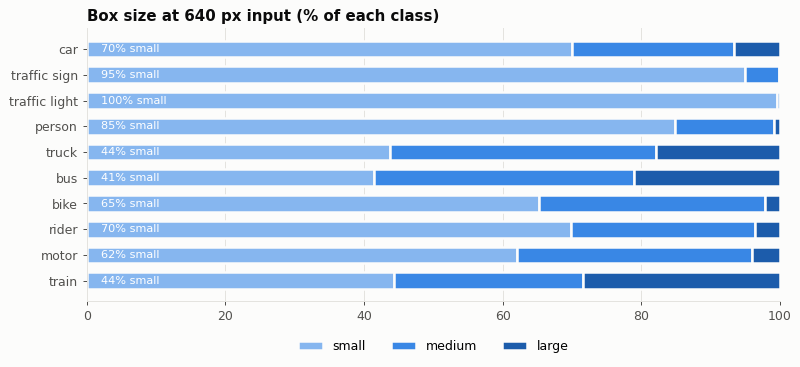

In [4]:
SCALE = 640 / 1280
b = boxes.assign(
    w=(boxes.x2 - boxes.x1) * SCALE,
    h=(boxes.y2 - boxes.y1) * SCALE,
)
b["area"] = b.w * b.h
b["size"] = pd.cut(b.area, [-np.inf, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])

size_share = (b.groupby("category", observed=True)["size"].value_counts(normalize=True)
              .unstack().mul(100))
order = box_counts.index[::-1]           # same order as the class chart, largest class on top
size_share = size_share.loc[order]

fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(size_share))
for col, color in zip(["small", "medium", "large"], RAMP):
    ax.barh(size_share.index, size_share[col], left=left, color=color, height=0.65,
            label=col, edgecolor="#fcfcfb", linewidth=2)
    left += size_share[col].values
ax.set_title("Box size at 640 px input (% of each class)")
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
for y, v in enumerate(size_share["small"].values):
    ax.annotate(f"{v:.0f}% small", (2, y), va="center", color="white" if v > 25 else INK, fontsize=9)
plt.tight_layout()

print(f"small overall: {(b['size'] == 'small').mean():.0%}")

In [5]:
# Median box height (px at 640 input) per class, and the share under 8 px tall: barely a few pixels to learn from
(b.groupby("category", observed=True)
   .agg(boxes=("h", "size"), median_h_px=("h", "median"), under_8px=("h", lambda s: (s < 8).mean() * 100))
   .round(1).sort_values("boxes", ascending=False))

,boxes,median_h_px,under_8px
category,,,
car,816661,16.9,16.5
traffic sign,274876,9.4,39.3
traffic light,213192,10.1,33.3
person,104700,26.0,3.2
truck,34259,33.9,3.9
bus,13285,35.0,3.9
bike,8234,26.2,2.7
rider,5171,29.5,5.1
motor,3454,25.5,6.5


## 3. Driving conditions

Image-level attributes. The question for training: is there enough night, rain and snow for the model to cope with them, or will it only work in daylight? Phase 7's CARLA demo will run in different weathers, so this matters later too.

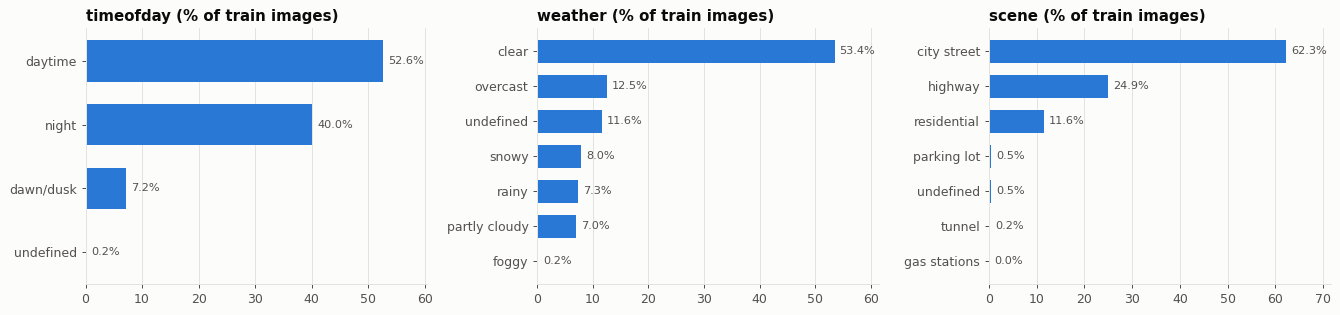

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["timeofday", "weather", "scene"]):
    hbar(ax, train_images[col].value_counts(normalize=True).mul(100), f"{col} (% of train images)", fmt="{:.1f}%")
plt.tight_layout()

In [7]:
# Time of day x weather (% of train images): which combinations are rare?
pd.crosstab(train_images.timeofday, train_images.weather, normalize=True).mul(100).round(1)

weather,clear,foggy,overcast,partly cloudy,rainy,snowy,undefined
timeofday,,,,,,,
dawn/dusk,2.9,0.0,1.6,0.8,0.5,0.6,0.8
daytime,17.8,0.1,10.8,6.1,3.6,4.1,10.1
night,32.8,0.1,0.1,0.1,3.2,3.2,0.6
undefined,0.0,0.0,0.0,0.0,0.0,0.0,0.2


In [8]:
# Do night images contain fewer labelled objects? (Harder to see -> harder to label)
train_images.groupby("timeofday", observed=True).n_boxes.describe()[["count", "mean", "50%", "max"]].round(1)

,count,mean,50%,max
timeofday,,,,
dawn/dusk,5033.0,19.2,18.0,69.0
daytime,36800.0,19.9,19.0,89.0
night,28028.0,16.4,15.0,91.0
undefined,139.0,8.0,6.0,35.0


## 4. Occlusion and truncation

- **occluded**: partly hidden behind something else (a car behind a car)
- **truncated**: cut off by the image border

Both make an object harder to detect and its box less reliable for distance estimation in Phase 4, which reads depth inside the box.

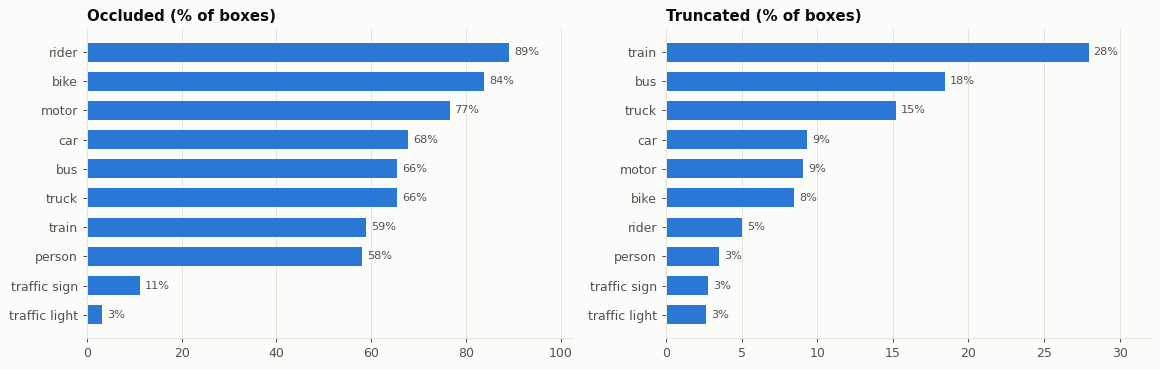

In [9]:
occ = train_boxes.groupby("category", observed=True)[["occluded", "truncated"]].mean().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hbar(axes[0], occ.occluded, "Occluded (% of boxes)", fmt="{:.0f}%")
hbar(axes[1], occ.truncated, "Truncated (% of boxes)", fmt="{:.0f}%")
plt.tight_layout()

## 5. Where objects appear in the frame

A 2D histogram of box centres over all train boxes. Darker = more boxes. Vehicles cluster along the horizon band and the road; this is also why lane and distance logic can focus on the lower half of the image.

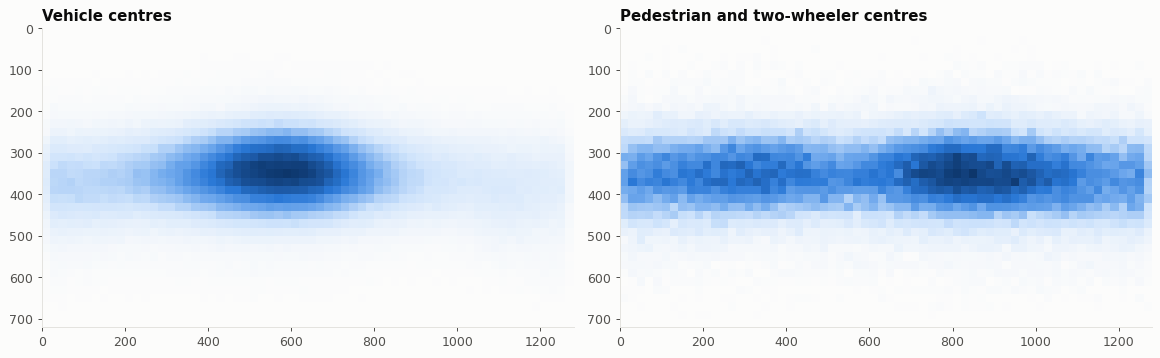

In [10]:
seq = LinearSegmentedColormap.from_list("blue_seq", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
cx = (train_boxes.x1 + train_boxes.x2) / 2
cy = (train_boxes.y1 + train_boxes.y2) / 2

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, cats, title in [
    (axes[0], ["car", "truck", "bus"], "Vehicle centres"),
    (axes[1], ["person", "rider", "bike", "motor"], "Pedestrian and two-wheeler centres"),
]:
    m = train_boxes.category.isin(cats)
    ax.hist2d(cx[m], cy[m], bins=[64, 36], range=[[0, 1280], [0, 720]], cmap=seq)
    ax.set_xlim(0, 1280); ax.set_ylim(720, 0)
    ax.set_aspect("equal"); ax.grid(False)
    ax.set_title(title)
plt.tight_layout()

## 6. Label quality

Problems to filter when converting to YOLO format.

In [11]:
w, h = boxes.x2 - boxes.x1, boxes.y2 - boxes.y1
checks = pd.Series({
    "zero or negative width/height": ((w <= 0) | (h <= 0)).sum(),
    "smaller than 2 px (original res)": ((w > 0) & (h > 0) & ((w < 2) | (h < 2))).sum(),
    "outside the image": ((boxes.x1 < 0) | (boxes.y1 < 0) | (boxes.x2 > 1280) | (boxes.y2 > 720)).sum(),
    "images with undefined weather": (images.weather == "undefined").sum(),
    "images with undefined timeofday": (images.timeofday == "undefined").sum(),
    "images with no lane labels": (images.n_lanes == 0).sum(),
}, name="count")
out_of = np.array([len(boxes)] * 3 + [len(images)] * 3)   # first 3 checks are per box, the rest per image
checks.to_frame().assign(percent=(checks / out_of * 100).round(3))

,count,percent
zero or negative width/height,447,0.030
smaller than 2 px (original res),437,0.030
outside the image,0,0.000
images with undefined weather,9291,11.614
images with undefined timeofday,174,0.217
images with no lane labels,3834,4.792


## 7. What the labels look like

One day and one night image from val, with boxes drawn. Thin boxes, colour only by class family.

blue = vehicles, orange = pedestrians / riders / two-wheelers, yellow = traffic lights and signs


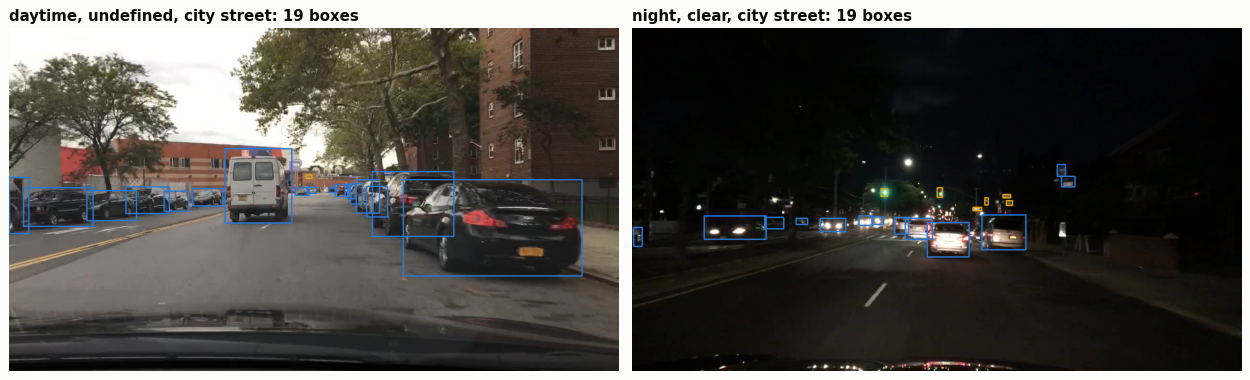

In [12]:
FAMILY = {"car": "vehicle", "truck": "vehicle", "bus": "vehicle", "train": "vehicle",
          "person": "vru", "rider": "vru", "bike": "vru", "motor": "vru",
          "traffic light": "signal", "traffic sign": "signal"}
COLOR_BGR = {"vehicle": (214, 120, 42), "vru": (52, 104, 235), "signal": (0, 161, 237)}  # blue, orange, yellow


def show(ax, image_id, split="val"):
    img = cv2.imread(str(DATA / "images" / "100k" / split / f"{image_id}.jpg"))
    for r in boxes[(boxes.split == split) & (boxes.image_id == image_id)].itertuples():
        cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), COLOR_BGR[FAMILY[r.category]], 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_axis_off()
    meta = images[(images.split == split) & (images.image_id == image_id)].iloc[0]
    ax.set_title(f"{meta.timeofday}, {meta.weather}, {meta.scene}: {meta.n_boxes} boxes")


val_images = images[images.split == "val"]
day = val_images[(val_images.timeofday == "daytime") & val_images.n_boxes.between(15, 25)].iloc[0].image_id
night = val_images[(val_images.timeofday == "night") & val_images.n_boxes.between(15, 25)].iloc[0].image_id
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
show(axes[0], day)
show(axes[1], night)
plt.tight_layout()
print("blue = vehicles, orange = pedestrians / riders / two-wheelers, yellow = traffic lights and signs")

## Findings

Numbers are for the train split unless noted. Val matches train within 0.2 percentage points for every class (section 1), so val mAP will be a fair measure.

**1. Classes are heavily imbalanced.** Cars are 55% of all boxes; there are 238 cars per motorcycle and 5,251 per train. Bikes, riders and motorcycles each appear in only 3–6% of images, trains in 0.1%.
→ Drop `train` (136 train boxes, and no trains on CARLA's roads): the class set is the other 9. When picking the training subset, **oversample images that contain rare classes** instead of sampling at random, and report mAP per class, since the overall number will be dominated by cars.

**2. Most objects are small.** At 640 px input, 79% of boxes are below 32×32 px. Traffic lights are 100% small (median height 10 px) and a third of traffic lights and signs are under 8 px tall. Vehicles and people are larger (median 17–35 px).
→ Expect low mAP on lights and signs with YOLO n/s at 640. For the braking demo, vehicles and people matter most. Train at 640 first; try a larger input size (e.g. 960) only if VRAM and time allow, and compare small-object mAP.

**3. Night is well covered, weather labels less so.** 53% daytime, 40% night, 7% dawn/dusk. Rain and snow are 7–8% each. But 12% of images have `undefined` weather, and 82% of night images are labelled `clear` (cloud cover is hard to judge in the dark).
→ Evaluate day vs night separately (reliable labels, big enough groups). Treat weather as a rough tag only. Night images have fewer labelled objects (median 15 vs 19), so night recall may be the weak spot.

**4. Occlusion is the norm, truncation is not.** 58–89% of vehicles, people and two-wheelers are marked occluded (riders 89%: they overlap their bike); truncation is 3–28%, highest for long vehicles cut off at the frame edge.
→ The `occluded` flag is applied generously, so it's of little use for filtering. For distance estimation (Phase 4), occluded boxes mix the object's depth with whatever hides it; use a robust statistic (median depth in the box, lower part of the box) rather than the mean.

**5. Objects sit in a horizon band.** Box centres concentrate between y ≈ 300 and 450 px. Vehicles peak just left of centre (the road ahead); pedestrians and two-wheelers spread across the frame and peak on the right (US roads: right-hand traffic, sidewalk on the right). The sample frames also show the ego car's dashboard or hood along the bottom edge.
→ The CARLA camera has no hood in view and a different mounting height: a domain gap to keep in mind when the BDD-trained detector runs in the simulator.

**6. Label errors are rare.** 447 boxes have zero or negative size and 437 more are under 2 px (0.06% together); none extend outside the image.
→ Drop both groups during YOLO conversion.

**Decisions for the next step (YOLO conversion):** 9 classes (no `train`); remove degenerate and < 2 px boxes; build a training subset of about 20k images with rare-class oversampling; keep the full 10k val set for evaluation, tagged by time of day.